In [1]:
import numpy as np

In [2]:
train_features = np.load("train_preprocessed.npy")
val_features = np.load("val_preprocessed.npy")
test_features = np.load("test_preprocessed.npy")

train_labels = np.load("y_train.npy")
val_labels = np.load("y_val.npy")
test_labels = np.load("y_test.npy")

print("Train features:", train_features.shape)
print("Validation features:", val_features.shape)
print("Test features:", test_features.shape)

print("Train labels:", train_labels.shape)
print("Validation labels:", val_labels.shape)
print("Test labels:", test_labels.shape)

Train features: (49000, 84)
Validation features: (10500, 84)
Test features: (10500, 84)
Train labels: (49000,)
Validation labels: (10500,)
Test labels: (10500,)


In [3]:
train_labels = train_labels.reshape(-1, 1)
val_labels = val_labels.reshape(-1, 1)
test_labels = test_labels.reshape(-1, 1)

print("Train labels:", train_labels.shape)
print("Validation labels:", val_labels.shape)
print("Test labels:", test_labels.shape)

Train labels: (49000, 1)
Validation labels: (10500, 1)
Test labels: (10500, 1)


In [28]:
def knn_predict(train_features, train_labels, evaluate_features, k):

    predictions = []
    epsilon = 1e-8

    train_labels = train_labels.ravel()

    for x in evaluate_features:

        distances = np.sqrt(
            np.sum((train_features - x) ** 2, axis=1)
        )

#فاصله‌ی اقلیدسی تصویر x را با تمام تصاویر Train حساب کن.
        nearest_indices = np.argsort(distances)[:k]
#argsort → شماره‌ی موقعیت‌ها را از نزدیک‌ترین تا دورترین مرتب می‌کند.
        nearest_distances = distances[nearest_indices]
        #فاصله‌ی همان همسایه‌ها را می‌گیرد.
        nearest_labels = train_labels[nearest_indices]

        weights = 1 / (nearest_distances + epsilon)
        #وزن‌دهی

        weighted_votes = {}

        for label, weight in zip(nearest_labels, weights):

            if label not in weighted_votes:
                weighted_votes[label] = 0

            weighted_votes[label] += weight
            #وزن این همسایه را به مجموع رأی کلاسش اضافه می‌کنیم.

        max_vote = max(weighted_votes.values())

        candidates = [
            label
            for label, vote in weighted_votes.items()
            if vote == max_vote
        ]

        if len(candidates) == 1:
            prediction = candidates[0]

        else:
            closest_candidate = None
            closest_distance = float("inf")

            for label in candidates:

                label_distances = nearest_distances[
                    nearest_labels == label
                ]

                current_distance = np.min(label_distances)

                if current_distance < closest_distance:
                    closest_distance = current_distance
                    closest_candidate = label

            prediction = closest_candidate

        predictions.append(prediction)

    return np.array(predictions).reshape(-1, 1)

In [17]:
k_values = [1, 3, 5, 7, 9]

validation_accuracies = {}

for k in k_values:

    predictions = knn_predict(
        train_features,
        train_labels,
        val_features,
        k
    )

    accuracy = np.mean(
        predictions.ravel() == val_labels.ravel()
    )

    validation_accuracies[k] = accuracy

    print(f"k = {k}, Validation Accuracy = {accuracy:.4f}")

k = 1, Validation Accuracy = 0.8463
k = 3, Validation Accuracy = 0.8620
k = 5, Validation Accuracy = 0.8624
k = 7, Validation Accuracy = 0.8654
k = 9, Validation Accuracy = 0.8626


In [18]:
best_k = max(
    validation_accuracies,
    key=validation_accuracies.get
)

print("Best k:", best_k)
print("Best Validation Accuracy:", validation_accuracies[best_k])

Best k: 7
Best Validation Accuracy: 0.8654285714285714


In [19]:
test_predictions = knn_predict(
    train_features,
    train_labels,
    test_features,
    best_k
)

print("Test predictions shape:", test_predictions.shape)
print("First 10 test predictions:", test_predictions[:10].ravel())

Test predictions shape: (10500, 1)
First 10 test predictions: ['1' '8' '1' '4' '7' '4' '1' '5' '0' '5']


In [20]:
test_accuracy = np.mean(
    test_predictions.ravel() == test_labels.ravel()
)

print("Final Test Accuracy:", test_accuracy)

Final Test Accuracy: 0.8638095238095238


In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels.ravel(),
    test_predictions.ravel()
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 867    0   18   29    3    0   75    0   10    0]
 [   8 1013    3   17    4    0    3    0    0    1]
 [  11    1  805   10  110    0  101    0    2    0]
 [  36    2   11  922   55    0   34    0    1    0]
 [   4    1   81   16  856    0  100    0    3    0]
 [   1    0    0    1    0  999    1   64    4   42]
 [ 201    1  126   20   80    0  621    0   11    0]
 [   0    0    0    0    0    7    0  968    0   42]
 [   3    0    7    5    5    0    9    6  970    3]
 [   0    0    0    0    0    4    0   37    0 1049]]


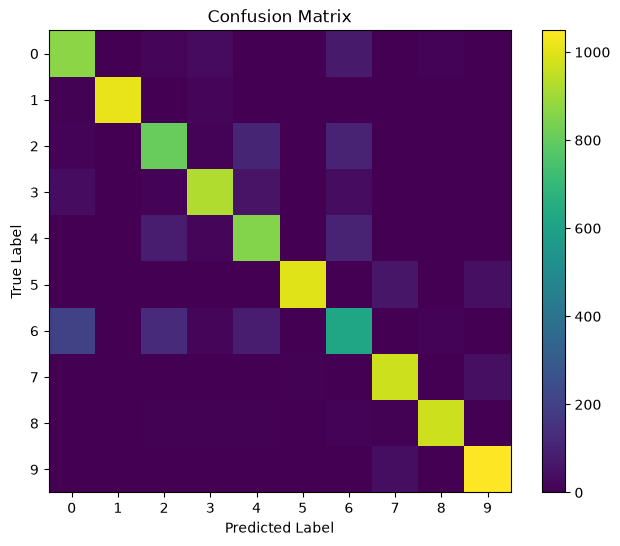

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()

In [23]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels.ravel(),
        test_predictions.ravel()
    )
)

              precision    recall  f1-score   support

           0       0.77      0.87      0.81      1002
           1       1.00      0.97      0.98      1049
           2       0.77      0.77      0.77      1040
           3       0.90      0.87      0.89      1061
           4       0.77      0.81      0.79      1061
           5       0.99      0.90      0.94      1112
           6       0.66      0.59      0.62      1060
           7       0.90      0.95      0.93      1017
           8       0.97      0.96      0.97      1008
           9       0.92      0.96      0.94      1090

    accuracy                           0.86     10500
   macro avg       0.86      0.86      0.86     10500
weighted avg       0.86      0.86      0.86     10500



In [24]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Class names:")
for i, name in enumerate(class_names):
    print(i, "->", name)

Class names:
0 -> T-shirt/top
1 -> Trouser
2 -> Pullover
3 -> Dress
4 -> Coat
5 -> Sandal
6 -> Shirt
7 -> Sneaker
8 -> Bag
9 -> Ankle boot
